In [3]:
import matplotlib.pyplot as plt 
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif" :"Computer Modern",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
}) 
import numpy as np
from numpy.polynomial.legendre import Legendre
from numpy.polynomial.legendre import leggauss

In [60]:
tol=1e-12
def gauss_radau_left(N, a=-1.0, b=1.0, tol=1e-12):
    
    """
    Left Gauss–Radau quadrature on [a,b] including x = -1.
    Based on:
        roots of (P_{N-1}(x) + P_N(x)) = 0
        w_i = (1 - x_i) / [N * P_{N-1}(x_i)]^2
        w_1 = 2 / N^2
    """
    # Legendre polynomials
    Pn   = Legendre.basis(N)
    Pn_1 = Legendre.basis(N-1)

    # Internal nodes: roots of P_{N-1}(x) + P_N(x)
    poly = Pn_1 + Pn
    roots = np.sort(poly.roots())

    # Remove any root numerically equal to -1
    roots = roots[roots > -1 + tol]

    # Combine with exact endpoint -1
    x_nodes = np.concatenate(([-1.0], roots))

    # Compute weights
    w = np.zeros_like(x_nodes)
    w[0]  = 2.0 / (N**2)
    w[1:] = (1 - roots) / ((N * Pn_1(roots))**2)

    # Map from [-1,1] → [a,b]
    t_nodes = 0.5 * (b - a) * (x_nodes + 1) + a
    w *= 0.5 * (b - a)
    return t_nodes, w

In [58]:
#This gives you n nodes 
N=6
L_N   = Legendre.basis(N)
L_Np1 = Legendre.basis(N-1)

# Internal nodes: roots of L_N(t) + L_{N+1}(t)
poly = L_N + L_Np1
roots = np.sort(poly.roots())
roots = poly.roots()
roots = np.sort(poly.roots())
print(roots[0])

-1.0000000000000004


In [6]:
Pn   = Legendre.basis(N)
Pn_1 = Legendre.basis(N-1)

# Internal nodes: roots of P_N(x) - P_{N-1}(x)
poly = Pn - Pn_1
roots = poly.roots()
print(roots)

[-0.92038029 -0.60397316 -0.12405038  0.39092855  0.80292983  1.        ]


In [7]:
Pn   = Legendre.basis(N)
Pn_1 = Legendre.basis(N-1)

# Internal nodes: roots of P_N(x) - P_{N-1}(x)
poly = Pn - Pn_1
roots = poly.roots()

x_nodes = roots
print(x_nodes)

[-0.92038029 -0.60397316 -0.12405038  0.39092855  0.80292983  1.        ]


In [8]:
# Legendre polynomials
Pn   = Legendre.basis(N)
Pn_1 = Legendre.basis(N-1)

# Internal nodes: roots of the sum of legendre polynomials P_{N-1}(x) + P_N(x)
roots = (Pn_1 + Pn).roots()

# Combine with exact endpoint -1
x_nodes = np.concatenate(([-1.0], roots))
print(x_nodes)
print(roots)

[-1.         -1.         -0.80292983 -0.39092855  0.12405038  0.60397316
  0.92038029]
[-1.         -0.80292983 -0.39092855  0.12405038  0.60397316  0.92038029]


In [9]:
import numpy as np
from numpy.polynomial.legendre import Legendre

def gauss_radau_left_infinite(N):
    """
    Classical Left Gauss–Radau quadrature on [-1,1]
    where the endpoint -1 is already included in the roots
    of P_N + P_{N-1}, then mapped to [0,∞) using t = (1+τ)/(1−τ).
    """

    # Step 1: Legendre polynomials L_N and L_{N-1}
    L_N   = Legendre.basis(N)
    L_Nm1 = Legendre.basis(N-1)

    # Step 2: roots of L_N + L_{N-1}
    poly = L_N + L_Nm1
    tau_nodes = np.sort(poly.roots())   # includes -1 automatically
    tau_nodes[np.isclose(tau_nodes, -1, atol=1e-12)] = -1.0    # Force exact -1 endpoint

    # Step 3: classical Gauss–Radau weights on [-1,1]
    w_tau = np.zeros_like(tau_nodes)

    # Endpoint weight at τ = -1
    w_tau[0] = 2.0 / (N**2)

    # Interior weights
    w_tau[1:] = (1 - tau_nodes[1:]) / ((N**2) * (L_Nm1(tau_nodes[1:]))**2)

    # Step 4: infinite-horizon mapping τ → t
    t_nodes = (1 + tau_nodes) / (1 - tau_nodes)

    # Step 5: transformed weights: multiply by dt/dτ
    dt_dtau = 2.0 / (1 - tau_nodes)**2
    w_t = w_tau * dt_dtau

    return t_nodes, w_t

t_nodes , weights = gauss_radau_left_infinite(5)
print(t_nodes)
print(weights)

[ 0.          0.16246611  0.71353049  2.61215545 16.51184796]
[4.00000000e-02 3.01486425e-01 9.15580903e-01 3.67103959e+00
 4.40718931e+01]


In [10]:
def gauss_radau_left_log_mapping_shen(N, s=1.0):
    """
    Left Gauss–Radau quadrature on [-1,1], mapped to [0,+∞)
    using Shen & Wang (2009) logarithmic mapping (Eq. 2.16):

        t = (s/2)*ln((3+tau)/(1-tau))

    Much smoother than the log(4/(1-tau)^2) mapping.
    """

    # Step 1
    L_N   = Legendre.basis(N)
    L_Np1 = Legendre.basis(N-1)

    # Step 2: nodes
    poly = L_N + L_Np1
    tau_nodes = np.sort(poly.roots())
    tau_nodes[np.isclose(tau_nodes, -1, atol=1e-12)] = -1.0

    # Step 3: weights
    w_tau = np.zeros_like(tau_nodes)
    w_tau[0] = 2.0 / N**2
    w_tau[1:] = (1 - tau_nodes[1:]) / (N**2 * (L_N(tau_nodes[1:]))**2)

    # Step 4: Shen–Wang log mapping
    t_nodes = (s/2.0) * np.log((3 + tau_nodes) / (1 - tau_nodes))

    # Step 5: dt/dtau = (2s)/((3+tau)*(1-tau))
    dt_dtau = (2.0 * s) / ((3 + tau_nodes) * (1 - tau_nodes))

    w_t = w_tau * dt_dtau

    return t_nodes, w_t

t_nodes , weights = gauss_radau_left_log_mapping_shen(5)
print(t_nodes)
print(weights)

[0.         0.14068065 0.44334053 0.91423137 1.76352861]
[0.02777778 0.15801984 0.2619712  0.40957675 0.89953429]


In [11]:
import numpy as np
from numpy.polynomial.legendre import Legendre

def gauss_radau_left_log_mapping(N):
    """
    Left Gauss–Radau quadrature on [-1,1] using the nodes
    from roots of L_N + L_{N+1}, mapped to t = log(4 / (1 - tau)^2).
    """

    # Step 1: Legendre polynomials
    L_N   = Legendre.basis(N)
    L_Np1 = Legendre.basis(N-1)

    # Step 2: roots of L_N + L_{N+1}  (includes tau = -1)
    poly = L_N + L_Np1
    tau_nodes = np.sort(poly.roots())

    # force exact -1 for safety
    tau_nodes[np.isclose(tau_nodes, -1, atol=1e-12)] = -1.0

    # Step 3: classical Gauss–Radau weights on [-1,1]
    w_tau = np.zeros_like(tau_nodes)

    # weight at tau = -1
    w_tau[0] = 2.0 / (N**2)

    # interior weights
    w_tau[1:] = (1 - tau_nodes[1:]) / ((N**2) * (L_N(tau_nodes[1:]))**2)

    # Step 4: LOG mapping:  t = log(4 / (1 - tau)^2)
    t_nodes = np.log(4.0 / (1 - tau_nodes)**2)

    # Step 5: weight mapping: dt/dtau = 2 / (1 - tau)
    dt_dtau = 2.0 / (1 - tau_nodes)

    w_t = w_tau * dt_dtau

    return t_nodes, w_t

t_nodes , weights = gauss_radau_left_log_mapping(5)
print(t_nodes)
print(weights)

[0.         0.3010874  1.07711171 2.56860934 5.72575536]
[0.08       0.51870145 1.06864851 2.03260333 5.03338005]


In [12]:
#This gives you n+1 nodes
N=5
L_N   = Legendre.basis(N)
L_Np1 = Legendre.basis(N+1)
# Internal nodes: roots of L_N(t) + L_{N+1}(t)
poly = L_N + L_Np1
roots_1 = np.sort(poly.roots())
roots = poly.roots()
print(roots)
print(roots_1)

[-1.         -0.80292983 -0.39092855  0.12405038  0.60397316  0.92038029]
[-1.         -0.80292983 -0.39092855  0.12405038  0.60397316  0.92038029]


In [59]:
t_nodes, weights= gauss_radau_left(5)
print(t_nodes, weights)
print(sum(t_nodes))
print(sum(weights))

[0.08       0.4462078  0.62365305 0.56271203 0.28742712]
[-1.         -0.72048027 -0.16718086  0.44631397  0.88579161] [0.08       0.4462078  0.62365305 0.56271203 0.28742712]
-0.5555555555555562
2.000000000000025


In [14]:
t_nodes, weights= gauss_radau_left_log_mapping(10)
print(t_nodes, weights)
print(sum(t_nodes))
print(sum(weights))

[0.         0.07386292 0.25130554 0.54145847 0.96215428 1.54450891
 2.34451176 3.47321737 5.19693769 8.47933132] [0.02       0.12482246 0.23161953 0.351582   0.49482407 0.6787934
 0.93845848 1.35815338 2.20972954 5.10789016]
22.867288268085062
11.515873015875144


In [15]:
import numpy as np
from numpy.polynomial.legendre import Legendre
def gauss_radau_right(N, a=-1.0, b=1.0, tol=1e-12):

    """
    Right Gauss–Radau quadrature on [a,b] including x = +1.
    Based on:
        roots of (P_N(x) - P_{N-1}(x)) = 0
        w_i = (1 + x_i) / [N * P_{N-1}(x_i)]^2
        w_N = 2 / N^2
    """
    
    # Legendre polynomials
    Pn   = Legendre.basis(N)
    Pn_1 = Legendre.basis(N-1)

    # Internal nodes: roots of P_N(x) - P_{N-1}(x)
    poly = Pn - Pn_1
    roots = np.sort(poly.roots())

    #  Remove any root numerically equal to +1
    roots = roots[roots < 1 - tol]

    #Combine with exact endpoint +1
    x_nodes = np.concatenate((roots, [1.0]))
    print(x_nodes[-1])

    # Compute weights
    w = np.zeros_like(x_nodes)
    w[-1] = 2.0 / (N**2)
    w[:-1] = (1 + roots) / ((N * Pn_1(roots))**2)

    # Map from [-1,1] → [a,b]
    t_nodes = 0.5 * (b - a) * (x_nodes + 1) + a
    w *= 0.5 * (b - a)
    return t_nodes, w

t_nodes , weights = gauss_radau_right(5)
print(t_nodes)
print(weights)

1.0
[-0.88579161 -0.44631397  0.16718086  0.72048027  1.        ]
[0.28742712 0.56271203 0.62365305 0.4462078  0.08      ]


In [16]:
#This gives you n nodes 
N=5
L_N   = Legendre.basis(N)
L_Np1 = Legendre.basis(N-1)
# Internal nodes: roots of L_N(t) + L_{N+1}(t)
poly = L_N - L_Np1
roots = np.sort(poly.roots())
roots = poly.roots()
roots = np.sort(poly.roots())
print(roots)

[-0.88579161 -0.44631397  0.16718086  0.72048027  1.        ]


In [17]:
t_nodes, weights= gauss_radau_right(1, a=-1, b =1, tol=1e-12)
print(t_nodes, weights)

1.0
[1.] [2.]


In [18]:
P4 = Legendre.basis(10)
P3 = Legendre.basis(9)
polynomial = P4 - P3
added_roots=np.sort(polynomial.roots())
print(added_roots)

[-0.97117518 -0.85122522 -0.64776669 -0.38066484 -0.0760592   0.23623447
  0.52564603  0.76384204  0.92748437  1.        ]


In [19]:
def gauss_lobatto_nodes_weights(N, a=-1.0, b=1.0):

    """
    Compute N Gauss–Lobatto nodes and weights on [a,b].
    N = total number of nodes (including endpoints).
    """
    
    if N < 2:
        raise ValueError("Need at least 2 Lobatto nodes")

    n = N - 1  # Polynomial degree (one less than number of nodes)
    Pn = Legendre.basis(n)
    x_int = np.sort(Pn.deriv().roots())  #  Roots of the derivate of P(N-1) or P'(N-1) 
    x_nodes = np.concatenate(([-1.0], x_int, [1.0]))

    w = np.zeros(N)
    w[0] = w[-1] = 2.0 / (n * (n + 1))
    for i in range(1, N-1):
        xi = x_nodes[i]
        w[i] = 2.0 / (n * (n + 1) * (Pn(xi)**2))

    # Map to [a, b]
    t_nodes = 0.5 * (b - a) * (x_nodes + 1) + a
    w = 0.5 * (b - a) * w
    return t_nodes, w

In [20]:
t, nodes = gauss_lobatto_nodes_weights(5, a=-1, b=1)
print(t)
print(nodes)

[-1.         -0.65465367  0.          0.65465367  1.        ]
[0.1        0.54444444 0.71111111 0.54444444 0.1       ]


In [21]:
N=5    
n = N - 1 
Pn = Legendre.basis(n)
x_int = np.sort(Pn.deriv().roots()) 
print(x_int)

[-6.54653671e-01 -2.85801407e-17  6.54653671e-01]


In [56]:
def gauss_legendre_nodes_weights(N, a=0.0, b=1.0):
    """
    N-point Gauss–Legendre quadrature on [a,b].
    Returns nodes t and weights w.
    """
    x, w = leggauss(N)               # nodes/weights on [-1,1]
    t = 0.5*(b-a)*(x+1) + a          # map nodes to [a,b]
    w = 0.5*(b-a)*w                  # scale weights
    return t, w

In [55]:
legendre_nodes, legendre_weights = gauss_legendre_nodes_weights(10, a=-2, b=2)
print(legendre_nodes)
print(legendre_weights)

[0.06667134 0.14945135 0.21908636 0.26926672 0.29552422 0.29552422
 0.26926672 0.21908636 0.14945135 0.06667134]
[-1.94781306 -1.73012673 -1.35881914 -0.86679079 -0.29774868  0.29774868
  0.86679079  1.35881914  1.73012673  1.94781306]
[0.13334269 0.2989027  0.43817273 0.53853344 0.59104845 0.59104845
 0.53853344 0.43817273 0.2989027  0.13334269]


In [24]:
Radau_nodes, Radau_weights = gauss_legendre_nodes_weights(6, a=-1, b=1)
print(Radau_nodes)
print(Radau_weights)

[-0.93246951 -0.66120939 -0.23861919  0.23861919  0.66120939  0.93246951]
[0.17132449 0.36076157 0.46791393 0.46791393 0.36076157 0.17132449]


In [25]:
Radau_nodes, Radau_weights = gauss_lobatto_nodes_weights(4, a=-1, b=1)
print(Radau_nodes)
print(Radau_weights)

[-1.        -0.4472136  0.4472136  1.       ]
[0.16666667 0.83333333 0.83333333 0.16666667]


In [26]:
from scipy.integrate import quad

f1 = lambda x: np.exp(x)   # or any function you want
f2=  lambda x: np.exp(-x)
a, b = -1, 1
I_exact_f1, _ = quad(f1, a, b)
I_exact_f2,_= quad(f2,a,b)
I_exact_f3, _ = quad(f2, 0, np.inf)
print("Exact integral =", I_exact_f1)
print("Exact integral =", I_exact_f2)
print("Exact integral =", I_exact_f3)

Exact integral = 2.350402387287603
Exact integral = 2.350402387287603
Exact integral = 1.0


In [27]:
N = 1000
x_nodes, w = gauss_radau_right(N, a, b)
I_radau = np.sum(f1(x_nodes) * w)
print("Gauss–Radau integral =", I_radau)

1.0
Gauss–Radau integral = 2.350402387279027


In [28]:
def f(t):
    return np.exp(-t)      
N = 200
t_nodes, W = gauss_radau_left_infinite(N)
I_radau = np.sum(f(t_nodes) * W)
print("Integral approximation =", I_radau)
print(len(t_nodes))
print(len(W))

Integral approximation = 0.9999999999999332
200
200


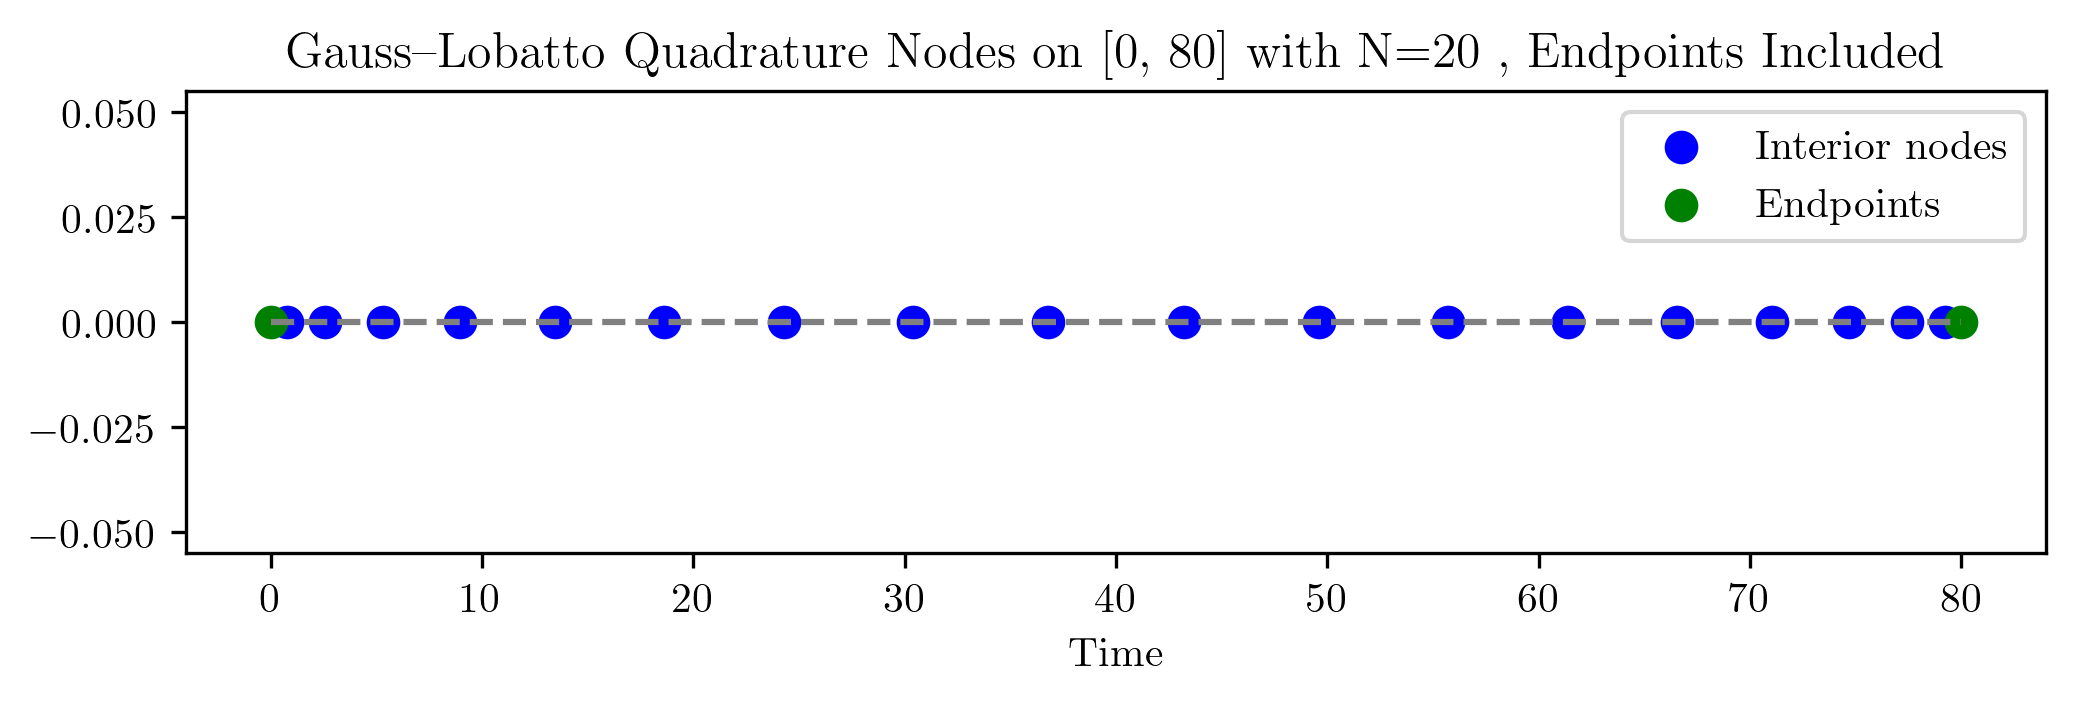

[0.21052632 1.28948493 2.28727209 3.22527056 4.07965999 4.82836911
 5.45201929 5.93446216 6.26320411 6.42973146 6.42973146 6.26320411
 5.93446216 5.45201929 4.82836911 4.07965999 3.22527056 2.28727209
 1.28948493 0.21052632]


In [ ]:
# Generate nodes and weights
lobatto_nodes, weights = gauss_lobatto_nodes_weights(20, a=0, b=80)

# Plot setup
plt.figure(figsize=(8, 2), dpi=300)
plt.hlines(0, 0, 80, colors='gray', linestyles='--')

# Interior nodes (blue)
plt.scatter(lobatto_nodes[1:-1], np.zeros_like(lobatto_nodes[1:-1]),
            color='blue', s=50, label='Interior nodes')

# Endpoints (green)
plt.scatter([lobatto_nodes[0], lobatto_nodes[-1]], [0, 0],
            color='green', s=50, label='Endpoints')

plt.xlabel('Time')
plt.title('Gauss–Lobatto Quadrature Nodes on [0, 80] with N=20 , Endpoints Included')
plt.legend()
plt.grid(False)
# Add text below the axis
# plt.text(20, -0.03, 'Endpoints Included.', ha='center', fontsize=12)
plt.show()

[ 0.27485603  1.44112291  3.51062287  6.43532113 10.14672374 14.55785277
 19.56531992 25.05175645 30.88856595 36.93893915 43.06106085 49.11143405
 54.94824355 60.43468008 65.44214723 69.85327626 73.56467887 76.48937713
 78.55887709 79.72514397]


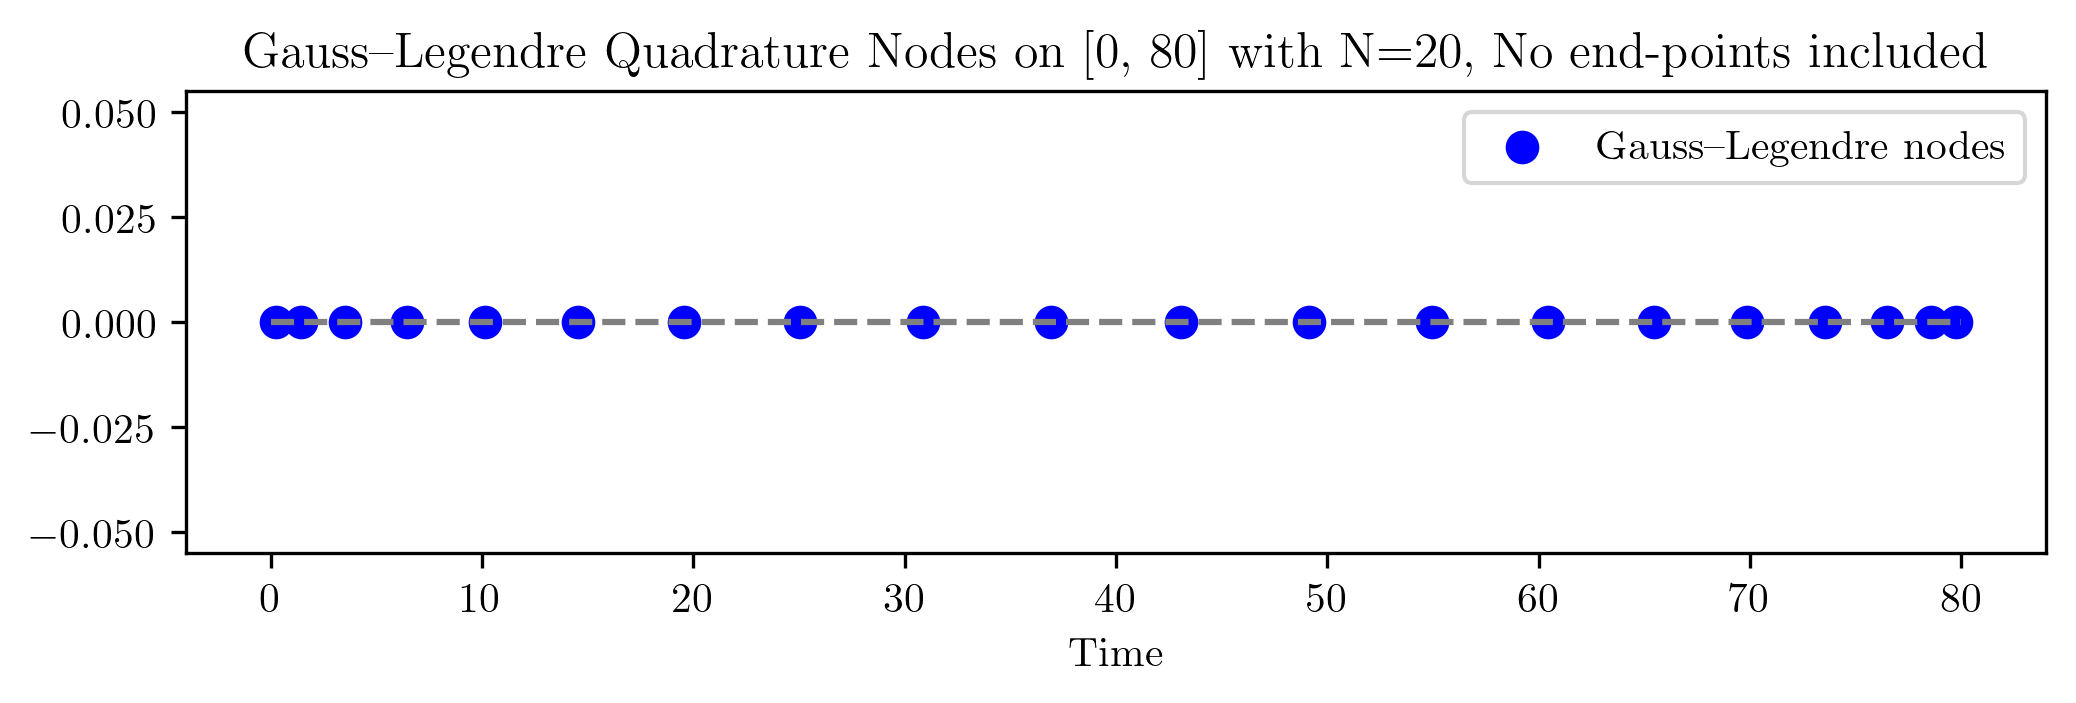

In [45]:
# Generate nodes and weights
legendre_nodes, weights = gauss_legendre_nodes_weights(20, a=0, b=80)
print(legendre_nodes)

# Plot
plt.figure(figsize=(8, 2), dpi=300)
plt.scatter(legendre_nodes, np.zeros_like(legendre_nodes),
            color='blue', s=50, label='Gauss–Legendre nodes')
plt.hlines(0, 0, 80, colors='gray', linestyles='--')
plt.xlabel('Time')
plt.title('Gauss–Legendre Quadrature Nodes on [0, 80] with N=20, No end-points included')
plt.legend()
plt.grid(False)
# plt.xlim(0, 1)
#Uncomment this below to see the full image 
#plt.text(60, -0.03, 'Endpoints Excluded', ha='center', fontsize=12)
plt.show()

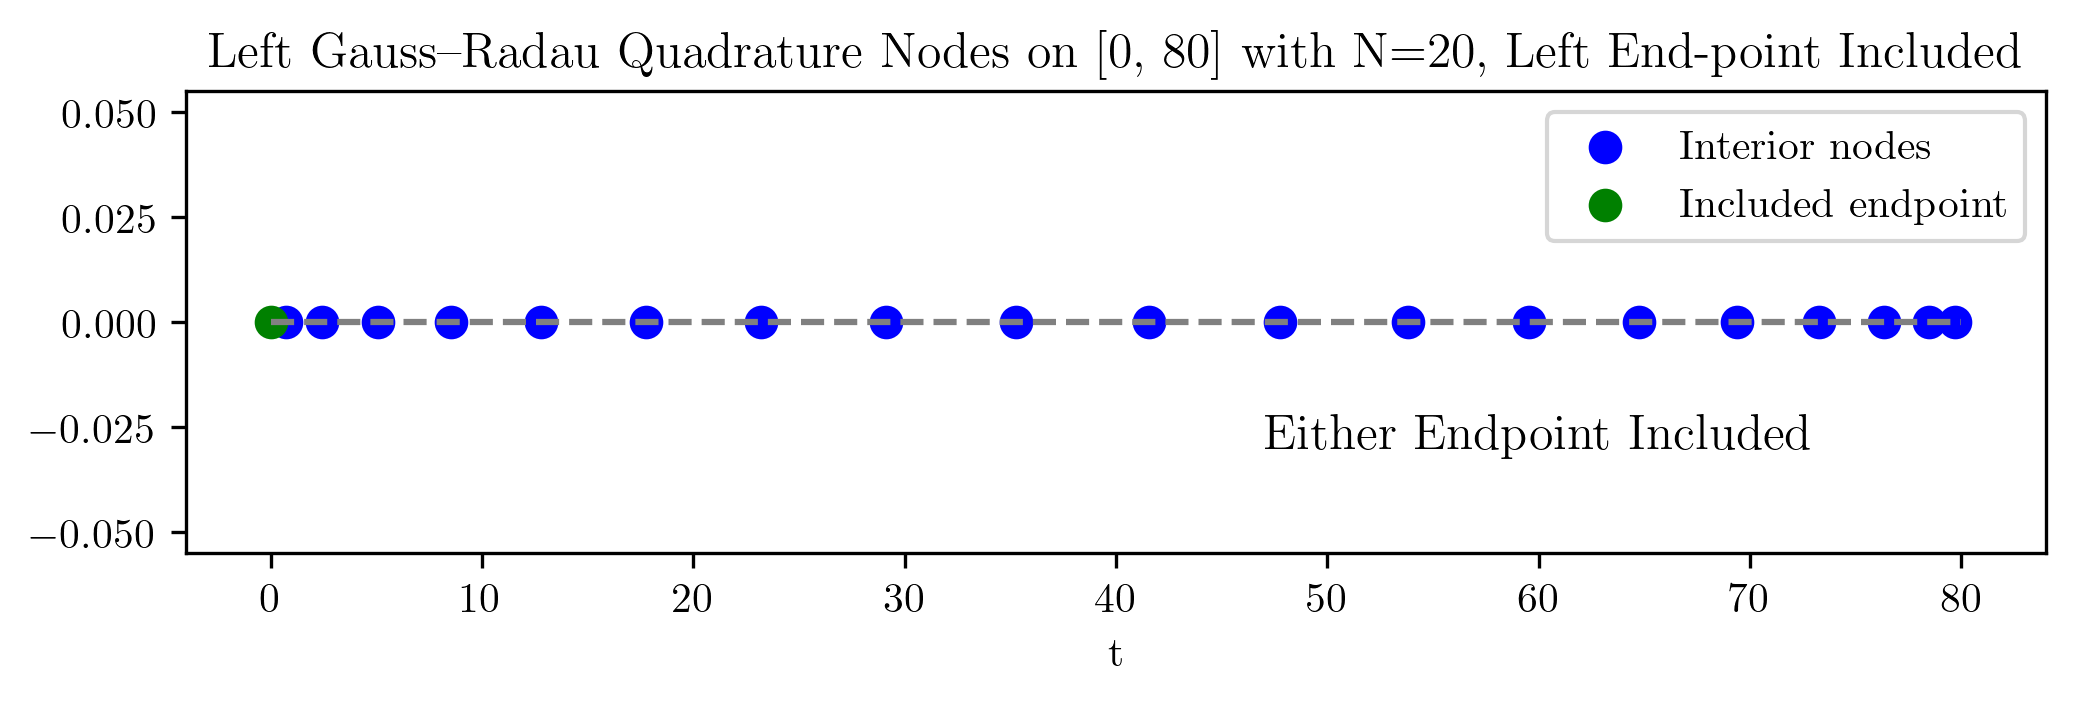

In [51]:
a,b=0,80
t_nodes, w = gauss_radau_left(20, a, b)
# Plot
plt.figure(figsize=(8, 2), dpi=300)
plt.hlines(0, 0, 80, colors='gray', linestyles='--')
# Interior nodes (all except the first)
plt.scatter(t_nodes[1:], np.zeros_like(t_nodes[1:]), color='blue', s=50, label='Interior nodes')
# Included endpoint (the first one)
plt.scatter(t_nodes[0], 0, color='green', s=50, label='Included endpoint')
# Annotation
plt.text(60, -0.03, 'Either Endpoint Included', ha='center', fontsize=12)
plt.xlabel('t')
plt.title(f'Left Gauss–Radau Quadrature Nodes on {[a,b]} with N=20, Left End-point Included')
plt.legend()
plt.grid(False)
plt.show()

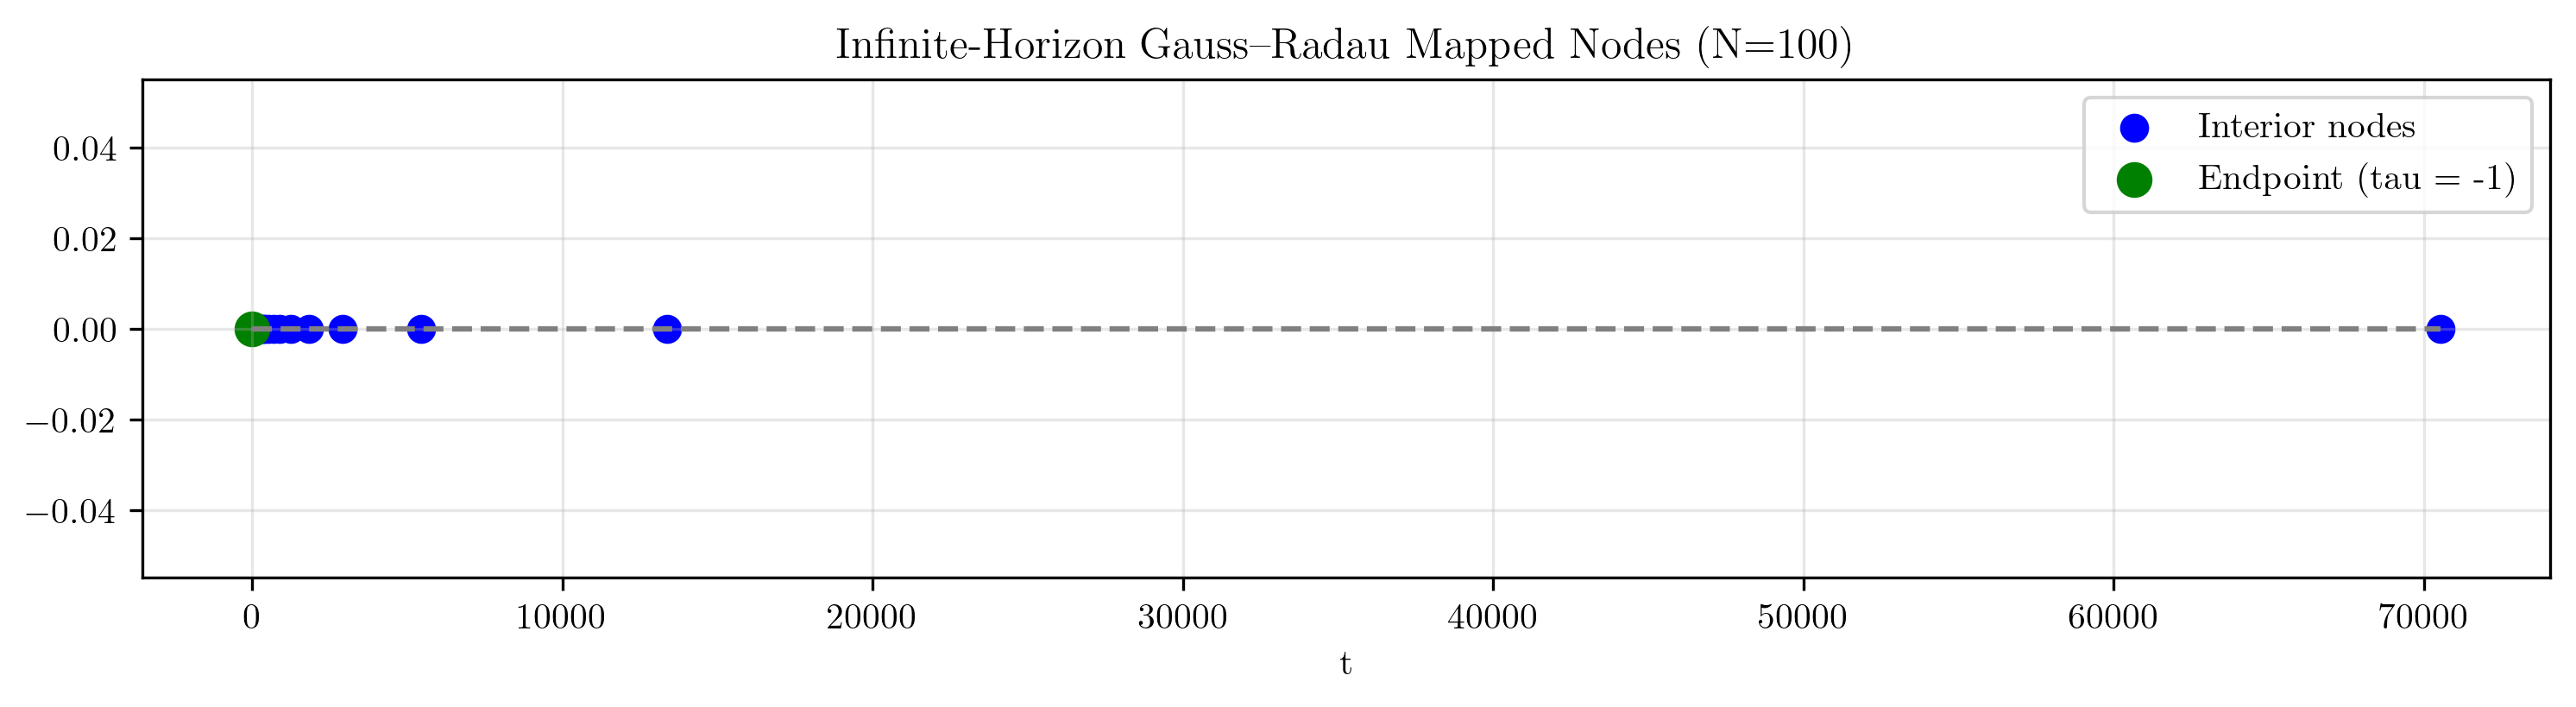

In [200]:
# Choose N and generate mapped nodes
N = 100
t_nodes, w = gauss_radau_left_infinite(N) 
k=10
t_nodes,w= t_nodes, w 
t_nodes,w=k*t_nodes,k*w

plt.figure(figsize=(12, 2.5), dpi=300)
plt.hlines(0, 0, max(t_nodes), colors='gray', linestyles='--')

# Interior nodes (all except the first one)
plt.scatter(t_nodes[1:], 
            np.zeros_like(t_nodes[1:]),
            color='blue', s=50, 
            label='Interior nodes')

# Endpoint node (tau = -1 → t = 0)
plt.scatter(t_nodes[0], 
            0, 
            color='green', s=80, 
            label='Endpoint (tau = -1)')

plt.xlabel("t")
plt.title(f"Infinite-Horizon Gauss–Radau Mapped Nodes (N={N})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

[0.         0.00363412 0.0121831  0.02562078 0.04394774 0.06716606
 0.09527851 0.12828852 0.16620012 0.20901795]


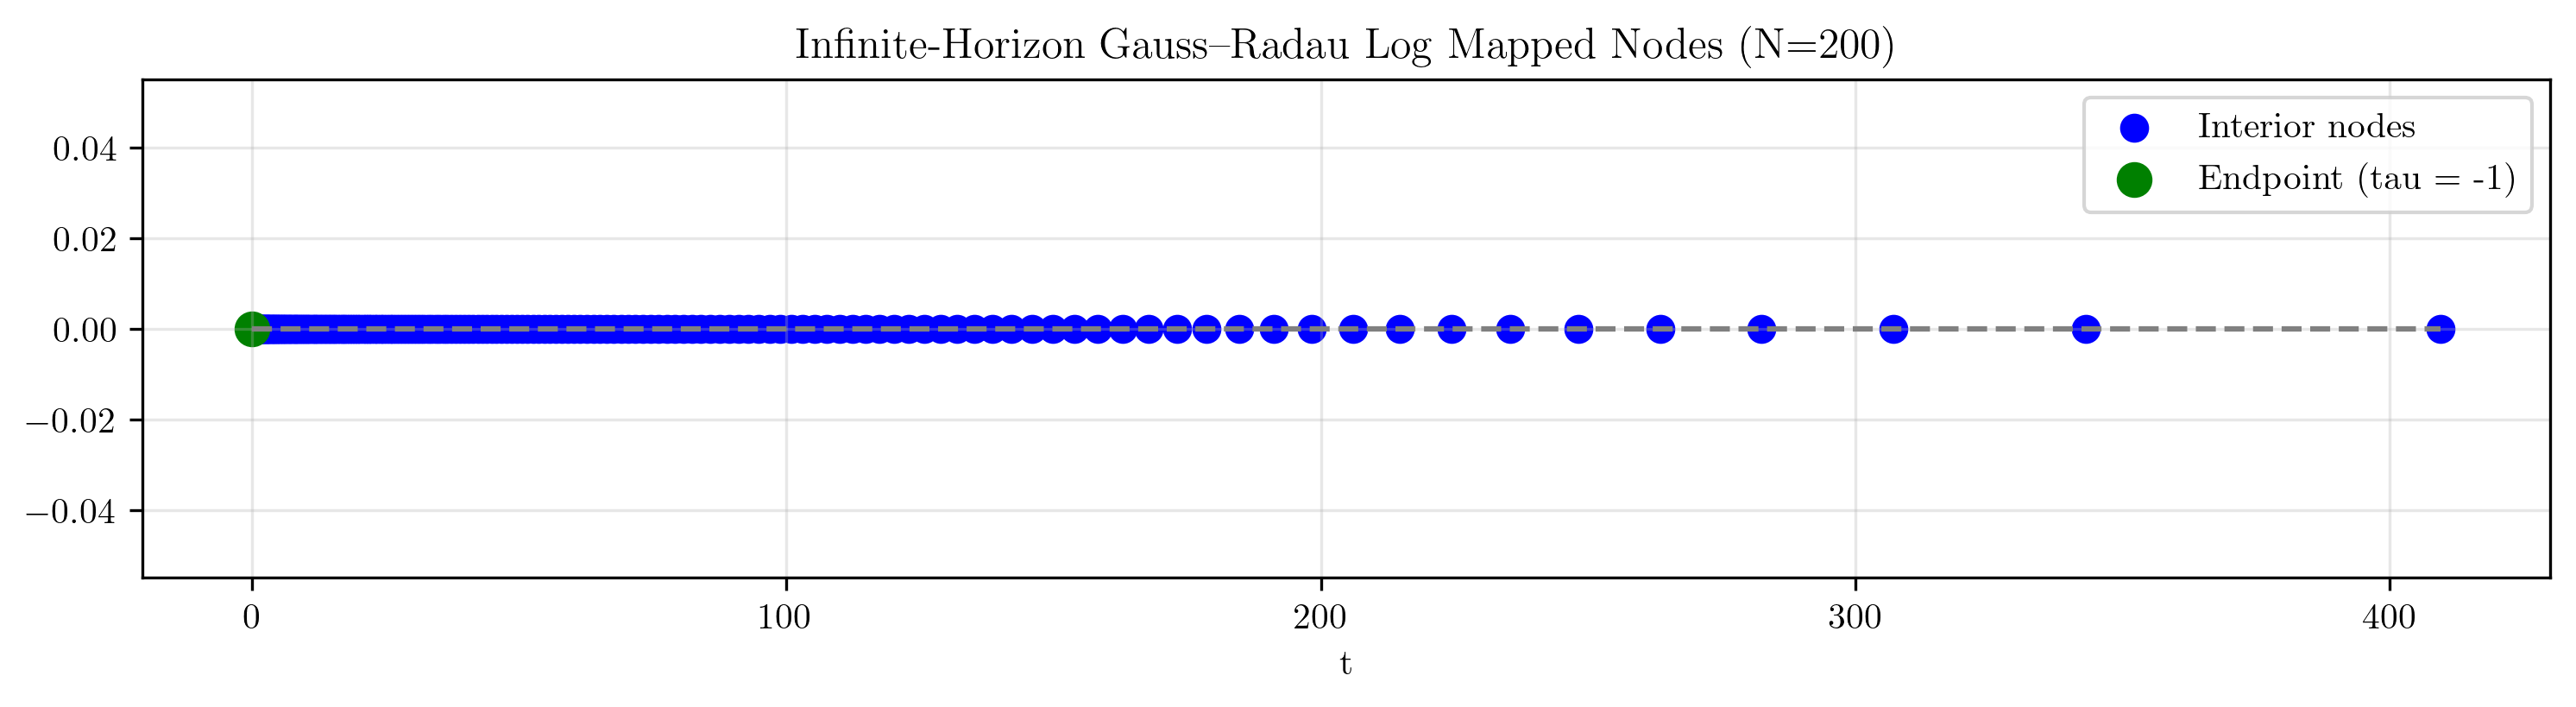

In [201]:
# Choose N and generate mapped nodes
N = 200
k=20
t_nodes, w = gauss_radau_left_log_mapping(N)   
t_nodes, w = k*t_nodes, k*w
print(t_nodes[:10])

plt.figure(figsize=(12, 2.5), dpi=300)
plt.hlines(0, 0, max(t_nodes), colors='gray', linestyles='--')

# Interior nodes (all except the first one)
plt.scatter(t_nodes[1:], 
            np.zeros_like(t_nodes[1:]),
            color='blue', s=50, 
            label='Interior nodes')

# Endpoint node (tau = -1 → t = 0)
plt.scatter(t_nodes[0], 
            0, 
            color='green', s=80, 
            label='Endpoint (tau = -1)')

plt.xlabel("t")
plt.title(f"Infinite-Horizon Gauss–Radau Log Mapped Nodes (N={N})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

[0.00000000e+00 4.54243894e-03 1.52265604e-02 3.20157219e-02
 5.49045339e-02 8.38872008e-02 1.18956627e-01 1.60104310e-01
 2.07320329e-01 2.60593355e-01 3.19910677e-01 3.85258222e-01
 4.56620584e-01 5.33981056e-01 6.17321664e-01 7.06623203e-01
 8.01865274e-01 9.03026327e-01 1.01008370e+00 1.12301368e+00
 1.24179153e+00 1.36639153e+00 1.49678706e+00 1.63295063e+00
 1.77485395e+00 1.92246794e+00 2.07576284e+00 2.23470825e+00
 2.39927316e+00 2.56942605e+00 2.74513491e+00 2.92636733e+00
 3.11309055e+00 3.30527151e+00 3.50287691e+00 3.70587329e+00
 3.91422708e+00 4.12790465e+00 4.34687238e+00 4.57109671e+00]


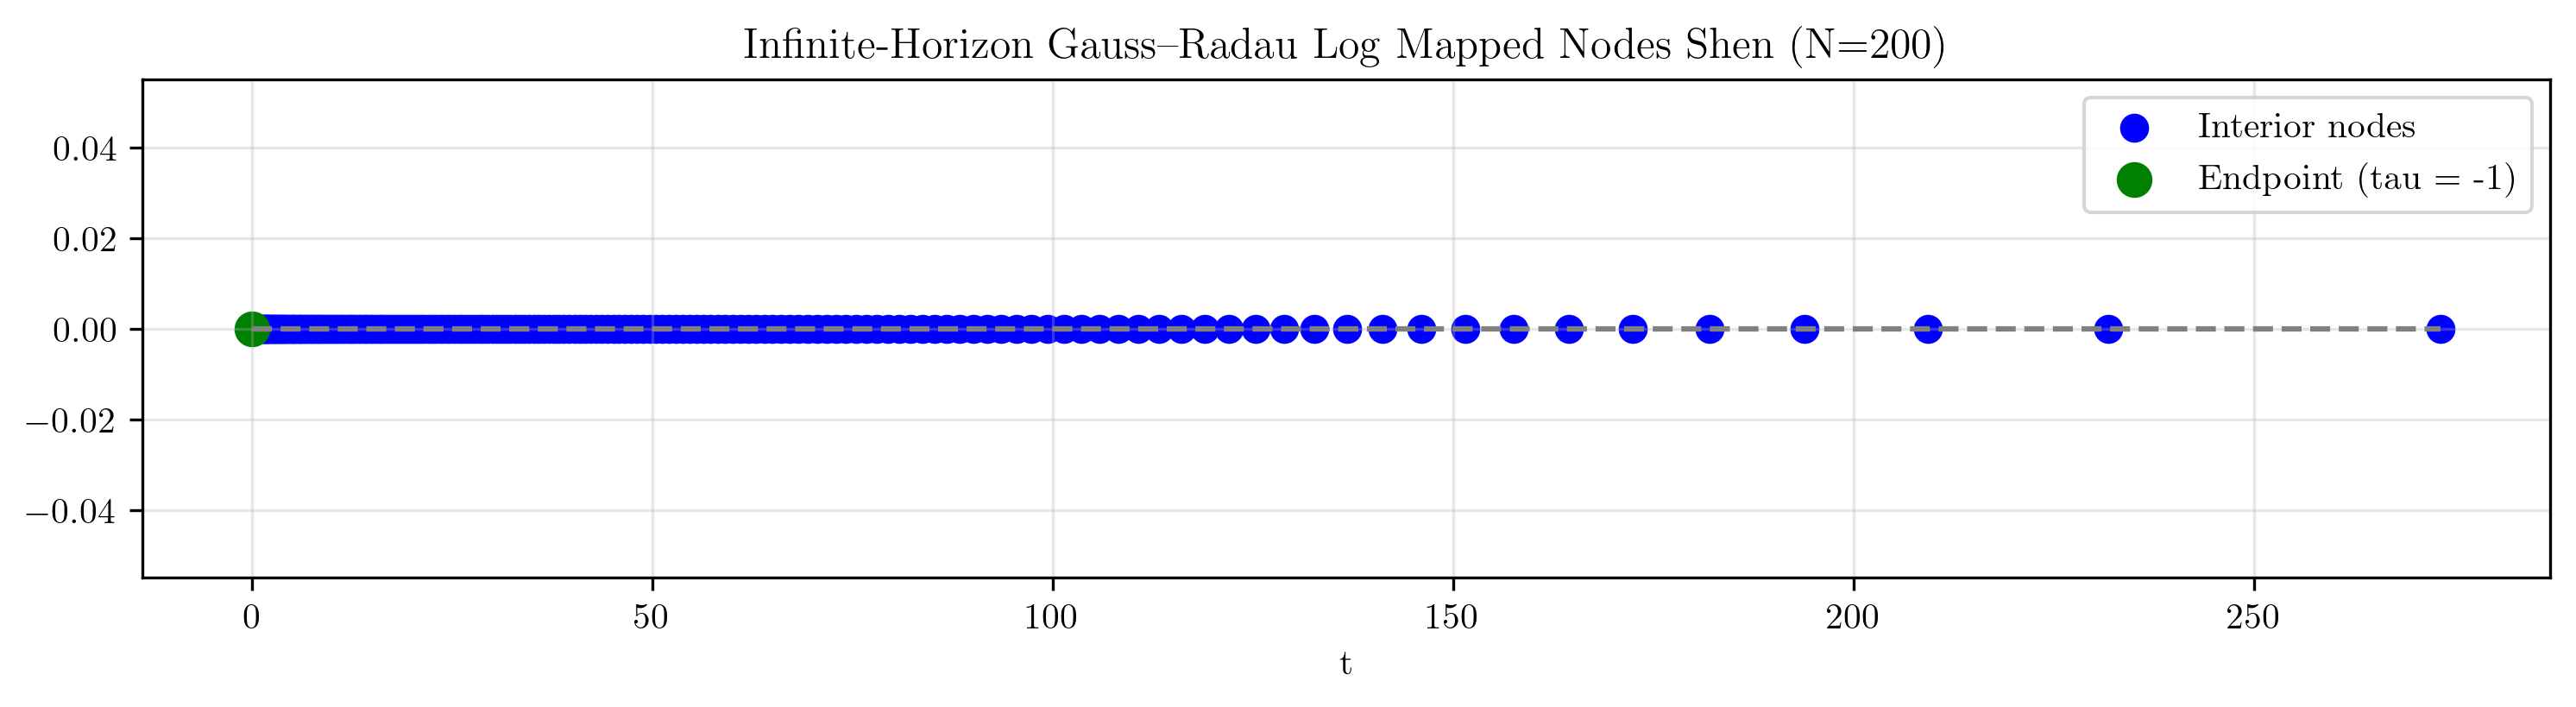

In [202]:
# Choose N and generate mapped nodes
N = 200
t_nodes, w = gauss_radau_left_log_mapping_shen(N,s=50)   
print(t_nodes[:40])

plt.figure(figsize=(12, 2.5), dpi=300)
plt.hlines(0, 0, max(t_nodes), colors='grey', linestyles='--')

# Interior nodes (all except the first one)
plt.scatter(t_nodes[1:], 
            np.zeros_like(t_nodes[1:]),
            color='blue', s=50, 
            label='Interior nodes')

# Endpoint node (tau = -1 → t = 0)
plt.scatter(t_nodes[0], 
            0, 
            color='green', s=80, 
            label='Endpoint (tau = -1)')

plt.xlabel("t")
plt.title(f"Infinite-Horizon Gauss–Radau Log Mapped Nodes Shen (N={N})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [203]:
N=5
from scipy.special import roots_jacobi
nodes_jacobi , w_jacobi  = roots_jacobi(N-1, 0,1)
nodes_jacobi= np.sort(np.asarray(nodes_jacobi,float))
print(nodes_jacobi)
print(w_jacobi)

[-0.72048027 -0.16718086  0.44631397  0.88579161]
[0.12472388 0.51939019 0.81385827 0.54202765]


In [204]:
x,w= gauss_radau_left(N,-1,1)
#x,w=gauss_radau_right(N,-1,1)
print(x)
print(w)

[-1.         -0.72048027 -0.16718086  0.44631397  0.88579161]
[0.08       0.4462078  0.62365305 0.56271203 0.28742712]


In [205]:
def LGR_nodes_jacobi(N):
    if N == 1:
        colloc = np.array([-1.0], dtype=float)
        w_lgr  = np.array([2.0], dtype=float)
    else:
        x, w_gj = roots_jacobi(N-1, 0.0, 1.0)
        x   = np.sort(np.asarray(x, float))
        wgj = np.asarray(w_gj, float)

        colloc = np.concatenate(([-1.0], x))
        w_int  = wgj / (1.0 + x)
        w_lgr  = np.concatenate(([2.0/(N**2)], w_int))

    tau_s = np.concatenate((colloc, [1.0]))   # include endpoint

    return colloc, w_lgr, tau_s

colloc, w_lgr, tau_s=LGR_nodes_jacobi(5)
print(colloc)
print(f"Weights are {w_lgr}")
print(tau_s)

[-1.         -0.72048027 -0.16718086  0.44631397  0.88579161]
Weights are [0.08       0.4462078  0.62365305 0.56271203 0.28742712]
[-1.         -0.72048027 -0.16718086  0.44631397  0.88579161  1.        ]


In [206]:
def Gauss_radau_left_jacobi(N):
    # SciPy weight: (1 - x)^alpha (1 + x)^beta
    # Left Radau → weight includes (1 + x) → beta = 1
    # Right Radau → weight includes (1 - x) → beta = 0
    
    from scipy.special import roots_jacobi
    import numpy as np

    # Step 1: Jacobi interior nodes and weights
    x_int, w_jac = roots_jacobi(N-1, alpha=0, beta=1)

    # Step 2: Endpoint and its weight
    x0 = -1.0
    w0 = 2.0 / N**2

    # Step 3: Convert Jacobi weights → Radau weights
    w_int = w_jac / (1 + x_int)

    # Step 4: Assemble final nodes and weights
    x = np.concatenate(([x0], x_int))
    w = np.concatenate(([w0], w_int))
    x_full = np.concatenate((x,[1]))

    return x, x_full, w

x,x_full,w=Gauss_radau_left_jacobi(5)
print(x)
print(w)
print(x_full)


[-1.         -0.72048027 -0.16718086  0.44631397  0.88579161]
[0.08       0.4462078  0.62365305 0.56271203 0.28742712]
[-1.         -0.72048027 -0.16718086  0.44631397  0.88579161  1.        ]


In [ ]:
def Gauss_radau_right_jacobi(N):
    # SciPy weight: (1 - x)^alpha (1 + x)^beta
    # Left Radau → weight includes (1 + x) → beta = 1
    # Right Radau → weight includes (1 - x) → beta = 0
    
    from scipy.special import roots_jacobi
    import numpy as np

    # Step 1: Jacobi interior nodes and weights
    x_int, w_jac = roots_jacobi(N-1, alpha=1, beta=0)

    # Step 2: Endpoint and its weight
    x_end = 1.0
    w_end = 2.0 / N**2

    # Step 3: Convert Jacobi weights → Radau weights
    w_int = w_jac / (1 - x_int)

    # Step 4: Assemble final nodes and weights
    x = np.concatenate((x_int,[x_end]))
    w = np.concatenate((w_int, [w_end]))
    x_full = np.concatenate(([-1],x))

    return x, x_full, w

x,x_full,w=Gauss_radau_right_jacobi(5)
print(x)
print(w)
print(x_full)

[-0.88579161 -0.44631397  0.16718086  0.72048027  1.        ]
[0.28742712 0.56271203 0.62365305 0.4462078  0.08      ]
[-1.         -0.88579161 -0.44631397  0.16718086  0.72048027  1.        ]


In [138]:
x,w=gauss_radau_right(5,-1,1)
print(x)
print(w)

[-0.88579161 -0.44631397  0.16718086  0.72048027  1.        ]
[0.28742712 0.56271203 0.62365305 0.4462078  0.08      ]
